In [4]:
%pip install pandas


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [102]:

from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles in current directory:")
for item in Path.cwd().iterdir():
    print(item.name)


Current working directory:
d:\smart inventory demand analytics project\notebooks

Files in current directory:
business_summary.csv
inventory_analysis_results.csv
inventory_data_cleaning.ipynb


In [184]:

from pathlib import Path

project_path = Path.cwd().parent

print("Project folder:", project_path)
print("\nFiles and folders in project folder:")

for item in project_path.iterdir():
    print(item.name)


Project folder: d:\smart inventory demand analytics project

Files and folders in project folder:
Data
excel
notebooks
powerbi
README.md
sql


In [232]:
import pandas as pd
from pathlib import Path

candidates = [
    Path.cwd() / "Data" / "smart_inventory.csv",
    Path.cwd().parent / "Data" / "smart_inventory.csv",
    Path.cwd() / "smart_inventory.csv",
]

csv_path = next((p for p in candidates if p.exists()), None)

if csv_path is None:
    raise FileNotFoundError("Could not find smart_inventory.csv")

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("File location:", csv_path)
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
File location: d:\smart inventory demand analytics project\Data\smart_inventory.csv
Shape: (10000, 17)


,Order_ID,Order_Date,Product_ID,Product_Name,Category,Supplier,Warehouse,Region,Quantity_Sold,Unit_Price,Cost_Per_Unit,Current_Stock,Reorder_Level,Lead_Time_Days,Customer_ID,Discount,Order_Status
0,ORD00001,2025-08-03,P007,Power Bank,Electronics,GlobalMart,Delhi,Central,8,9721.28,5828.17,188,40,8,C1397,0.0,Completed
1,ORD00002,2026-04-05,P008,Smart Watch,Wearables,Prime Supplies,Hyderabad,Central,2,11058.98,6143.90,293,21,13,C0857,0.0,Completed
2,ORD00003,2025-09-01,P010,Headphones,Audio,TechSource,Delhi,West,15,1513.32,1230.20,189,81,4,C1843,0.0,Cancelled
3,ORD00004,2025-12-06,P009,Fitness Band,Wearables,Nova Distributors,Bangalore,South,12,2378.20,1917.30,13,28,11,C1452,0.0,Cancelled
4,ORD00005,2025-04-16,P008,Smart Watch,Wearables,Nova Distributors,Hyderabad,South,4,1964.25,1562.59,49,23,3,C0402,0.0,Completed


In [233]:
df.shape

(10000, 17)

In [234]:
df.columns

Index(['Order_ID', 'Order_Date', 'Product_ID', 'Product_Name', 'Category',
       'Supplier', 'Warehouse', 'Region', 'Quantity_Sold', 'Unit_Price',
       'Cost_Per_Unit', 'Current_Stock', 'Reorder_Level', 'Lead_Time_Days',
       'Customer_ID', 'Discount', 'Order_Status'],
      dtype='object')

In [235]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        10000 non-null  object 
 1   Order_Date      10000 non-null  object 
 2   Product_ID      10000 non-null  object 
 3   Product_Name    10000 non-null  object 
 4   Category        10000 non-null  object 
 5   Supplier        10000 non-null  object 
 6   Warehouse       10000 non-null  object 
 7   Region          10000 non-null  object 
 8   Quantity_Sold   10000 non-null  int64  
 9   Unit_Price      10000 non-null  float64
 10  Cost_Per_Unit   10000 non-null  float64
 11  Current_Stock   10000 non-null  int64  
 12  Reorder_Level   10000 non-null  int64  
 13  Lead_Time_Days  10000 non-null  int64  
 14  Customer_ID     10000 non-null  object 
 15  Discount        10000 non-null  float64
 16  Order_Status    10000 non-null  object 
dtypes: float64(3), int64(4), object(

In [236]:
df.isnull().sum()

Order_ID          0
Order_Date        0
Product_ID        0
Product_Name      0
Category          0
Supplier          0
Warehouse         0
Region            0
Quantity_Sold     0
Unit_Price        0
Cost_Per_Unit     0
Current_Stock     0
Reorder_Level     0
Lead_Time_Days    0
Customer_ID       0
Discount          0
Order_Status      0
dtype: int64

In [237]:
df.duplicated().sum()

np.int64(0)

In [238]:
df.describe()

,Quantity_Sold,Unit_Price,Cost_Per_Unit,Current_Stock,Reorder_Level,Lead_Time_Days,Discount
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,7.997300,12517.542981,8582.365331,151.206400,59.582100,8.023500,0.054950
std,4.337923,18008.343637,12485.730149,87.494059,23.494762,3.733971,0.061525
min,1.000000,51.900000,31.580000,0.000000,20.000000,2.000000,0.000000
25%,4.000000,2699.380000,1822.485000,76.000000,39.000000,5.000000,0.000000
50%,8.000000,5863.775000,3940.740000,152.000000,59.000000,8.000000,0.050000
75%,12.000000,11917.387500,8364.427500,228.000000,80.000000,11.000000,0.100000
max,15.000000,84956.410000,68595.710000,300.000000,100.000000,14.000000,0.200000


In [239]:
# 1. Dataset dimensions
print("Dataset Shape:", df.shape)

Dataset Shape: (10000, 17)


In [240]:
# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Order_ID', 'Order_Date', 'Product_ID', 'Product_Name', 'Category', 'Supplier', 'Warehouse', 'Region', 'Quantity_Sold', 'Unit_Price', 'Cost_Per_Unit', 'Current_Stock', 'Reorder_Level', 'Lead_Time_Days', 'Customer_ID', 'Discount', 'Order_Status']


In [241]:
# 3. Data types and non-null counts
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        10000 non-null  object 
 1   Order_Date      10000 non-null  object 
 2   Product_ID      10000 non-null  object 
 3   Product_Name    10000 non-null  object 
 4   Category        10000 non-null  object 
 5   Supplier        10000 non-null  object 
 6   Warehouse       10000 non-null  object 
 7   Region          10000 non-null  object 
 8   Quantity_Sold   10000 non-null  int64  
 9   Unit_Price      10000 non-null  float64
 10  Cost_Per_Unit   10000 non-null  float64
 11  Current_Stock   10000 non-null  int64  
 12  Reorder_Level   10000 non-null  int64  
 13  Lead_Time_Days  10000 non-null  int64  
 14  Customer_ID     10000 non-null  object 
 15  Discount        10000 non-null  float64
 16  Order_Status    10000 non-null  object 
dtypes: float64

In [242]:
# 4. Missing values
print("\nMissing Values by Column:")
print(df.isnull().sum())



Missing Values by Column:
Order_ID          0
Order_Date        0
Product_ID        0
Product_Name      0
Category          0
Supplier          0
Warehouse         0
Region            0
Quantity_Sold     0
Unit_Price        0
Cost_Per_Unit     0
Current_Stock     0
Reorder_Level     0
Lead_Time_Days    0
Customer_ID       0
Discount          0
Order_Status      0
dtype: int64


In [243]:
# 5. Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())




Total Missing Values: 0


In [244]:
# 6. Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())




Duplicate Rows: 0


In [245]:
# 7. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))


Statistical Summary:


,Order_ID,Order_Date,Product_ID,Product_Name,Category,Supplier,Warehouse,Region,Quantity_Sold,Unit_Price,Cost_Per_Unit,Current_Stock,Reorder_Level,Lead_Time_Days,Customer_ID,Discount,Order_Status
count,10000,10000,10000,10000,10000,10000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000,10000.000000,10000
unique,10000,546,20,20,9,5,5,4,NaN,NaN,NaN,NaN,NaN,NaN,1990,NaN,3
top,ORD00001,2025-03-06,P003,USB-C Cable,Accessories,Reliable Traders,Hyderabad,West,NaN,NaN,NaN,NaN,NaN,NaN,C0453,NaN,Completed
freq,1,32,545,545,2042,2024,2071,2546,NaN,NaN,NaN,NaN,NaN,NaN,14,NaN,6725
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.997300,12517.542981,8582.365331,151.206400,59.582100,8.023500,NaN,0.054950,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.337923,18008.343637,12485.730149,87.494059,23.494762,3.733971,NaN,0.061525,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,51.900000,31.580000,0.000000,20.000000,2.000000,NaN,0.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,2699.380000,1822.485000,76.000000,39.000000,5.000000,NaN,0.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.000000,5863.775000,3940.740000,152.000000,59.000000,8.000000,NaN,0.050000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.000000,11917.387500,8364.427500,228.000000,80.000000,11.000000,NaN,0.100000,NaN


In [246]:
# 8. First 5 rows
print("\nFirst 5 Rows:")
display(df.head())


First 5 Rows:


,Order_ID,Order_Date,Product_ID,Product_Name,Category,Supplier,Warehouse,Region,Quantity_Sold,Unit_Price,Cost_Per_Unit,Current_Stock,Reorder_Level,Lead_Time_Days,Customer_ID,Discount,Order_Status
0,ORD00001,2025-08-03,P007,Power Bank,Electronics,GlobalMart,Delhi,Central,8,9721.28,5828.17,188,40,8,C1397,0.0,Completed
1,ORD00002,2026-04-05,P008,Smart Watch,Wearables,Prime Supplies,Hyderabad,Central,2,11058.98,6143.90,293,21,13,C0857,0.0,Completed
2,ORD00003,2025-09-01,P010,Headphones,Audio,TechSource,Delhi,West,15,1513.32,1230.20,189,81,4,C1843,0.0,Cancelled
3,ORD00004,2025-12-06,P009,Fitness Band,Wearables,Nova Distributors,Bangalore,South,12,2378.20,1917.30,13,28,11,C1452,0.0,Cancelled
4,ORD00005,2025-04-16,P008,Smart Watch,Wearables,Nova Distributors,Hyderabad,South,4,1964.25,1562.59,49,23,3,C0402,0.0,Completed


In [247]:

# Convert Order_Date into datetime format
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

In [248]:
# Check the data type
print("Data type:", df["Order_Date"].dtype)

Data type: datetime64[ns]


In [249]:
# Display the first 5 dates
print(df["Order_Date"].head())


0   2025-08-03
1   2026-04-05
2   2025-09-01
3   2025-12-06
4   2025-04-16
Name: Order_Date, dtype: datetime64[ns]


In [250]:
# Check data types of all columns
print("DATA TYPES:")
print(df.dtypes)

DATA TYPES:
Order_ID                  object
Order_Date        datetime64[ns]
Product_ID                object
Product_Name              object
Category                  object
Supplier                  object
Warehouse                 object
Region                    object
Quantity_Sold              int64
Unit_Price               float64
Cost_Per_Unit            float64
Current_Stock              int64
Reorder_Level              int64
Lead_Time_Days             int64
Customer_ID               object
Discount                 float64
Order_Status              object
dtype: object


In [251]:
# Check missing values in each column
print("\nMISSING VALUES:")
print(df.isnull().sum())



MISSING VALUES:
Order_ID          0
Order_Date        0
Product_ID        0
Product_Name      0
Category          0
Supplier          0
Warehouse         0
Region            0
Quantity_Sold     0
Unit_Price        0
Cost_Per_Unit     0
Current_Stock     0
Reorder_Level     0
Lead_Time_Days    0
Customer_ID       0
Discount          0
Order_Status      0
dtype: int64


In [252]:
# Check total duplicate rows
print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())



DUPLICATE ROWS:
0


In [253]:

df.describe()


,Order_Date,Quantity_Sold,Unit_Price,Cost_Per_Unit,Current_Stock,Reorder_Level,Lead_Time_Days,Discount
count,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2025-10-02 20:12:20.160000,7.997300,12517.542981,8582.365331,151.206400,59.582100,8.023500,0.054950
min,2025-01-01 00:00:00,1.000000,51.900000,31.580000,0.000000,20.000000,2.000000,0.000000
25%,2025-05-20 00:00:00,4.000000,2699.380000,1822.485000,76.000000,39.000000,5.000000,0.000000
50%,2025-10-04 00:00:00,8.000000,5863.775000,3940.740000,152.000000,59.000000,8.000000,0.050000
75%,2026-02-18 00:00:00,12.000000,11917.387500,8364.427500,228.000000,80.000000,11.000000,0.100000
max,2026-06-30 00:00:00,15.000000,84956.410000,68595.710000,300.000000,100.000000,14.000000,0.200000
std,NaN,4.337923,18008.343637,12485.730149,87.494059,23.494762,3.733971,0.061525


In [254]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())


Missing values:
Order_ID          0
Order_Date        0
Product_ID        0
Product_Name      0
Category          0
Supplier          0
Warehouse         0
Region            0
Quantity_Sold     0
Unit_Price        0
Cost_Per_Unit     0
Current_Stock     0
Reorder_Level     0
Lead_Time_Days    0
Customer_ID       0
Discount          0
Order_Status      0
dtype: int64


In [255]:
# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())



Duplicate rows: 0


In [256]:
# Check dataset dimensions
print("\nDataset shape:", df.shape)



Dataset shape: (10000, 17)


In [257]:

# Display the first 5 rows
display(df.head())

,Order_ID,Order_Date,Product_ID,Product_Name,Category,Supplier,Warehouse,Region,Quantity_Sold,Unit_Price,Cost_Per_Unit,Current_Stock,Reorder_Level,Lead_Time_Days,Customer_ID,Discount,Order_Status
0,ORD00001,2025-08-03,P007,Power Bank,Electronics,GlobalMart,Delhi,Central,8,9721.28,5828.17,188,40,8,C1397,0.0,Completed
1,ORD00002,2026-04-05,P008,Smart Watch,Wearables,Prime Supplies,Hyderabad,Central,2,11058.98,6143.90,293,21,13,C0857,0.0,Completed
2,ORD00003,2025-09-01,P010,Headphones,Audio,TechSource,Delhi,West,15,1513.32,1230.20,189,81,4,C1843,0.0,Cancelled
3,ORD00004,2025-12-06,P009,Fitness Band,Wearables,Nova Distributors,Bangalore,South,12,2378.20,1917.30,13,28,11,C1452,0.0,Cancelled
4,ORD00005,2025-04-16,P008,Smart Watch,Wearables,Nova Distributors,Hyderabad,South,4,1964.25,1562.59,49,23,3,C0402,0.0,Completed


In [258]:
# Display the last 5 rows
display(df.tail())

,Order_ID,Order_Date,Product_ID,Product_Name,Category,Supplier,Warehouse,Region,Quantity_Sold,Unit_Price,Cost_Per_Unit,Current_Stock,Reorder_Level,Lead_Time_Days,Customer_ID,Discount,Order_Status
9995,ORD09996,2025-06-07,P011,Earbuds,Audio,Reliable Traders,Delhi,South,2,10557.81,8547.63,137,69,2,C1066,0.10,Completed
9996,ORD09997,2025-05-17,P013,Monitor,Computers,GlobalMart,Bangalore,Central,8,81872.78,49886.19,197,58,9,C0552,0.00,Returned
9997,ORD09998,2026-04-16,P016,Desk Lamp,Office,Nova Distributors,Delhi,North,12,16991.40,10170.22,164,26,7,C1179,0.05,Completed
9998,ORD09999,2025-02-08,P005,Webcam,Electronics,Reliable Traders,Mumbai,South,10,11671.78,8577.38,83,79,2,C0230,0.05,Returned
9999,ORD10000,2025-05-05,P016,Desk Lamp,Office,GlobalMart,Delhi,Central,3,4526.01,3299.14,176,99,4,C1041,0.20,Completed


In [259]:
# Check column names
print("Column names:")
print(df.columns.tolist())


Column names:
['Order_ID', 'Order_Date', 'Product_ID', 'Product_Name', 'Category', 'Supplier', 'Warehouse', 'Region', 'Quantity_Sold', 'Unit_Price', 'Cost_Per_Unit', 'Current_Stock', 'Reorder_Level', 'Lead_Time_Days', 'Customer_ID', 'Discount', 'Order_Status']


In [260]:
# Display sample dates
print(df["Order_Date"].head(10))


0   2025-08-03
1   2026-04-05
2   2025-09-01
3   2025-12-06
4   2025-04-16
5   2025-10-23
6   2025-03-04
7   2025-02-02
8   2026-02-02
9   2026-04-30
Name: Order_Date, dtype: datetime64[ns]


In [261]:

# Check the data type of Order_Date
print(df["Order_Date"].dtype)


datetime64[ns]


In [262]:

# Identify numerical columns
print(df.select_dtypes(include="number").columns.tolist())


['Quantity_Sold', 'Unit_Price', 'Cost_Per_Unit', 'Current_Stock', 'Reorder_Level', 'Lead_Time_Days', 'Discount']


In [263]:

# Calculate key business statistics
print("Total Quantity Sold:", df["Quantity_Sold"].sum())
print("Average Quantity Sold:", df["Quantity_Sold"].mean())
print("Total Current Stock:", df["Current_Stock"].sum())
print("Average Current Stock:", df["Current_Stock"].mean())
print("Average Unit Price:", df["Unit_Price"].mean())
print("Total Orders:", df["Order_ID"].nunique())


Total Quantity Sold: 79973
Average Quantity Sold: 7.9973
Total Current Stock: 1512064
Average Current Stock: 151.2064
Average Unit Price: 12517.542981
Total Orders: 10000


In [264]:

# Display all column names
print(df.columns.tolist())


['Order_ID', 'Order_Date', 'Product_ID', 'Product_Name', 'Category', 'Supplier', 'Warehouse', 'Region', 'Quantity_Sold', 'Unit_Price', 'Cost_Per_Unit', 'Current_Stock', 'Reorder_Level', 'Lead_Time_Days', 'Customer_ID', 'Discount', 'Order_Status']


In [265]:

# Calculate total quantity sold by product
product_sales = (
    df.groupby("Product_Name")["Quantity_Sold"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 best-selling products
print(product_sales.head(10))


Product_Name
USB-C Cable            4463
Monitor                4373
External SSD           4285
Fitness Band           4228
Webcam                 4154
Mechanical Keyboard    4132
Desk Lamp              4110
Printer                4109
Wireless Mouse         4076
Power Bank             4073
Name: Quantity_Sold, dtype: int64


In [266]:

# 1. Sales by category
print("===== SALES BY CATEGORY =====")
print(df.groupby("Category")["Quantity_Sold"].sum()
      .sort_values(ascending=False))

# 2. Revenue by product
df["Revenue"] = df["Quantity_Sold"] * df["Unit_Price"]

print("\n===== TOP 10 PRODUCTS BY REVENUE =====")
print(df.groupby("Product_Name")["Revenue"].sum()
      .sort_values(ascending=False).head(10))

# 3. Revenue by region
print("\n===== REVENUE BY REGION =====")
print(df.groupby("Region")["Revenue"].sum()
      .sort_values(ascending=False))

# 4. Stock alert
df["Stock_Status"] = df.apply(
    lambda row: "Low Stock"
    if row["Current_Stock"] <= row["Reorder_Level"]
    else "Sufficient Stock",
    axis=1
)

print("\n===== STOCK STATUS =====")
print(df["Stock_Status"].value_counts())

# 5. Profit analysis
df["Profit"] = (
    df["Quantity_Sold"] *
    (df["Unit_Price"] - df["Cost_Per_Unit"])
)

print("\n===== OVERALL BUSINESS METRICS =====")
print("Total Revenue:", round(df["Revenue"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Profit Margin (%):",
      round(df["Profit"].sum() / df["Revenue"].sum() * 100, 2))


===== SALES BY CATEGORY =====
Category
Accessories    16661
Office         12190
Computers      11929
Electronics    11837
Wearables       7955
Audio           7531
Storage         4285
Stationery      3988
Networking      3597
Name: Quantity_Sold, dtype: int64

===== TOP 10 PRODUCTS BY REVENUE =====
Product_Name
Monitor         2.199573e+08
Tablet          1.881088e+08
Laptop          1.874988e+08
External SSD    4.247187e+07
Office Chair    3.946448e+07
Printer         3.910552e+07
Desk Lamp       3.738918e+07
Fitness Band    3.514964e+07
Smart Watch     3.192287e+07
Webcam          2.739795e+07
Name: Revenue, dtype: float64

===== REVENUE BY REGION =====
Region
West       2.553639e+08
North      2.494927e+08
Central    2.480140e+08
South      2.478547e+08
Name: Revenue, dtype: float64

===== STOCK STATUS =====
Stock_Status
Sufficient Stock    8018
Low Stock           1982
Name: count, dtype: int64

===== OVERALL BUSINESS METRICS =====
Total Revenue: 1000725318.76
Total Profit: 31446

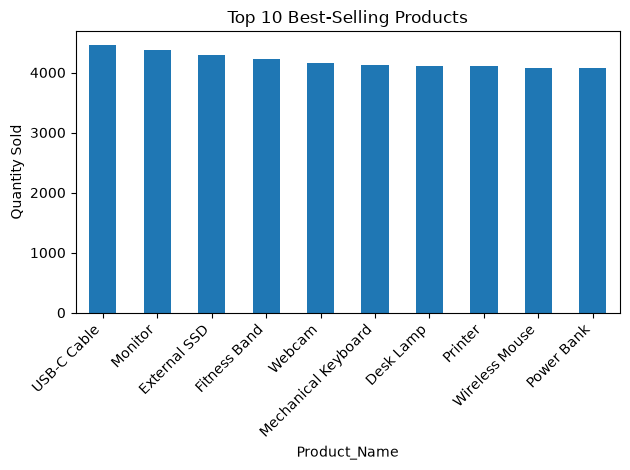

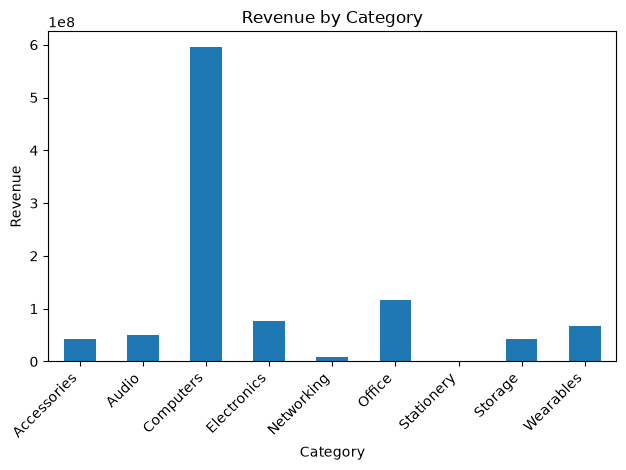

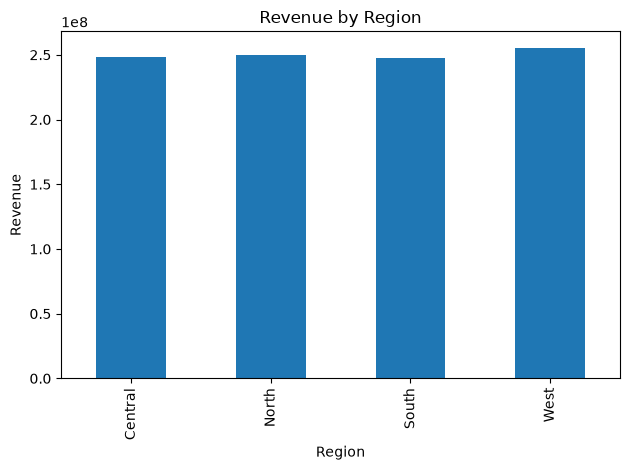

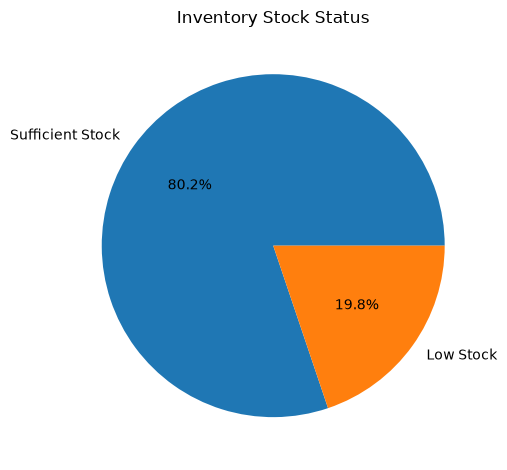

In [267]:
import matplotlib.pyplot as plt

# 1. Top 10 products by quantity sold
product_sales = df.groupby("Product_Name")["Quantity_Sold"].sum()
product_sales = product_sales.sort_values(ascending=False).head(10)

product_sales.plot(kind="bar", title="Top 10 Best-Selling Products")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
# 2. Revenue by category
df.groupby("Category")["Revenue"].sum().plot(
    kind="bar", title="Revenue by Category"
)
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 3. Revenue by region
df.groupby("Region")["Revenue"].sum().plot(
    kind="bar", title="Revenue by Region"
)
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

# 4. Stock status
df["Stock_Status"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", title="Inventory Stock Status"
)
plt.ylabel("")
plt.tight_layout()
plt.show()


In [268]:

%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [269]:

# FINAL BUSINESS SUMMARY

print("========== BUSINESS INSIGHTS ==========")

# Best-selling product
best_product = df.groupby("Product_Name")["Quantity_Sold"].sum().idxmax()
print("Best-Selling Product:", best_product)

# Highest revenue category
best_category = df.groupby("Category")["Revenue"].sum().idxmax()
print("Top Revenue Category:", best_category)

# Highest revenue region
best_region = df.groupby("Region")["Revenue"].sum().idxmax()
print("Top Revenue Region:", best_region)

# Low-stock records
low_stock = (df["Current_Stock"] <= df["Reorder_Level"]).sum()
print("Low-Stock Records:", low_stock)

# Revenue and profit
print("Total Revenue:", round(df["Revenue"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))

# Profit margin
margin = df["Profit"].sum() / df["Revenue"].sum() * 100
print("Profit Margin (%):", round(margin, 2))


========== BUSINESS INSIGHTS ==========
Best-Selling Product: USB-C Cable
Top Revenue Category: Computers
Top Revenue Region: West
Low-Stock Records: 1982
Total Revenue: 1000725318.76
Total Profit: 314466391.3
Profit Margin (%): 31.42


In [270]:

# Save the analyzed dataset
df.to_csv("inventory_analysis_results.csv", index=False)

# Create a business summary
summary = {
    "Total Records": len(df),
    "Total Quantity Sold": df["Quantity_Sold"].sum(),
    "Total Revenue": df["Revenue"].sum(),
    "Total Profit": df["Profit"].sum(),
    "Profit Margin (%)": round(
        df["Profit"].sum() / df["Revenue"].sum() * 100, 2
    ),
    "Best-Selling Product": df.groupby(
        "Product_Name"
    )["Quantity_Sold"].sum().idxmax(),
    "Top Revenue Category": df.groupby(
        "Category"
    )["Revenue"].sum().idxmax(),
    "Top Revenue Region": df.groupby(
        "Region"
    )["Revenue"].sum().idxmax(),
    "Low-Stock Records": (
        df["Current_Stock"] <= df["Reorder_Level"]
    ).sum()
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Metric", "Value"]
)

summary_df.to_csv("business_summary.csv", index=False)

print("Analysis dataset saved successfully!")
print("Business summary saved successfully!")
display(summary_df)


Analysis dataset saved successfully!
Business summary saved successfully!


,Metric,Value
0,Total Records,10000
1,Total Quantity Sold,79973
2,Total Revenue,1000725318.76
3,Total Profit,314466391.3
4,Profit Margin (%),31.42
5,Best-Selling Product,USB-C Cable
6,Top Revenue Category,Computers
7,Top Revenue Region,West
8,Low-Stock Records,1982


In [271]:

# Validate key calculations

print("Dataset shape:", df.shape)
print("Unique products:", df["Product_ID"].nunique())
print("Unique order IDs:", df["Order_ID"].nunique())

print("\nRevenue calculation check:")
print(
    "Revenue matches:",
    (df["Revenue"] == df["Quantity_Sold"] * df["Unit_Price"]).all()
)

print("\nProfit calculation check:")
expected_profit = (
    df["Quantity_Sold"] *
    (df["Unit_Price"] - df["Cost_Per_Unit"])
)
print("Profit matches:", (df["Profit"] == expected_profit).all())

print("\nInventory validation:")
print(
    "Low-stock rows:",
    (df["Current_Stock"] <= df["Reorder_Level"]).sum()
)
print(
    "Unique low-stock products:",
    df.loc[
        df["Current_Stock"] <= df["Reorder_Level"],
        "Product_ID"
    ].nunique()
)


Dataset shape: (10000, 20)
Unique products: 20
Unique order IDs: 10000

Revenue calculation check:
Revenue matches: True

Profit calculation check:
Profit matches: True

Inventory validation:
Low-stock rows: 1982
Unique low-stock products: 20


In [272]:

summary_df.to_csv("business_summary.csv", index=False)

print("business_summary.csv recreated successfully!")


business_summary.csv recreated successfully!
